# NB22: RELIC Visualization Cookbook
## Publication-Quality Plotting for Biogeochemical Simulation Output

This notebook demonstrates standard visualization patterns for RELIC simulation results,
covering time series, diurnal/seasonal cycles, scatter diagnostics, conservation audit
dashboards, and dependency graph visualization.

**Prerequisites**: NB17 (Real Case Simulation), NB19 (Post-processing)

---

## Architecture Anchor

This notebook is aligned with `docs\source\architecture_overview.md` and the relevant theory/API pages under `docs\source`.
All computations below are intended to use actual RELIC functors, the actual simulator or orchestration layer, and real validation pathways rather than notebook-defined pseudo-process equations.


## Learning Goals

- Build publication-grade figures directly from actual RELIC outputs and diagnostics.
- Compare time-series, flux-budget, response-curve, and dependency-graph visualization patterns.
- Check that figure styling preserves physical interpretation rather than hiding weak or noisy signals.


In [1]:
# Use only the standard library so notebook execution stays self-contained on Windows.
import asyncio
if hasattr(asyncio, "WindowsSelectorEventLoopPolicy"):
    asyncio.set_event_loop_policy(asyncio.WindowsSelectorEventLoopPolicy())

# --- Environment Guard (prevent OpenMP duplicate lib crash) ---
import os
import sys
from pathlib import Path

os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

%matplotlib inline

DEFAULT_PROJECT_ROOT = Path(os.environ.get("RELIC_PROJECT_ROOT", os.getcwd()))


def locate_project_root() -> Path:
    candidates = [
        Path.cwd().resolve(),
        *Path.cwd().resolve().parents,
        DEFAULT_PROJECT_ROOT,
    ]
    for candidate in candidates:
        if (candidate / "relic").is_dir() and (candidate / "docs" / "source" / "architecture_overview.md").is_file():
            return candidate.resolve()
    raise FileNotFoundError("Could not locate RELIC project root. Set RELIC_PROJECT_ROOT if needed.")


PROJECT_ROOT = locate_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import torch
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.gridspec import GridSpec

from relic.core.functor.functor_types import SpatialScale, TemporalScale, VariableKind
from relic.scientific.biosphere.photosynthesis.farquhar import FarquharPhotosynthesis
from relic.scientific.hydrosphere.evapotranspiration.penman_monteith import PenmanMonteithET
from relic.scientific.hydrosphere.soil_moisture.bucket import BucketSoilMoisture
from relic.scientific.pedosphere.decomposition.first_order import FirstOrderDecomposition

# Style settings for publication
plt.rcParams.update({
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'figure.dpi': 100,
    'savefig.dpi': 300,
    'figure.figsize': (10, 6),
})

print("[OK] Visualization environment ready")
print(f"  matplotlib version: {matplotlib.__version__}")
print(f"  torch version: {torch.__version__}")
print(f"  project root: {PROJECT_ROOT}")


[OK] Visualization environment ready
  matplotlib version: 3.10.0
  torch version: 2.13.0+cu130
  project root: <RELIC_ROOT>


## 1. Generating Actual RELIC Output Data

This section runs real RELIC scientific Functors to produce 30 days of
half-hourly forcing, carbon flux, and soil-moisture output for visualization.
The displayed runs call scientific kernels directly and update a local bucket
trajectory; they do not demonstrate the simulator's governed commit lifecycle.
NEE is defined from the two flux terms, so its residual plot checks the supplied
flux algebra, not an independent ecosystem carbon budget.


In [2]:
# ---------------------------------------------------------------
# References:
#   Farquhar et al. (1980) -- leaf photosynthesis.
#   Monteith (1965); Penman (1948) -- evapotranspiration forcing.
#   Manabe (1969) and bucket hydrology lineage -- soil moisture balance.
#   Parton et al. (1987) -- first-order litter and SOM decomposition.
# Mathematical expression:
#   NEE = R_eco - GPP
#   R_eco = R_dark + R_heterotrophic
#   theta(t+dt) = Bucket(theta, P, ET)
# Parameter meanings:
#   PAR: photosynthetically active radiation.
#   VPD: vapor pressure deficit.
#   theta: volumetric soil moisture.
#   GPP_candidate: perturbed RELIC photosynthesis run for comparison only.
# Units:
#   Temperature [K], VPD passed to kernels [Pa], water flux [kg m-2 s-1], precipitation depth [mm], carbon flux [kg C m-2 s-1].
# Domain/constraints:
#   Half-hour kernel experiment; synthetic forcings and respiratory components are explicitly prescribed.
# Sign convention:
#   Precipitation enters; ET removes water; NEE is outward positive.
# ---------------------------------------------------------------

def unwrap_update(value):
    return value.value if hasattr(value, "value") else value


dt_hours = 0.5
n_days = 30
n_steps = int(24 * n_days / dt_hours)
time_hours = torch.arange(n_steps, dtype=torch.float32) * dt_hours
days = time_hours / 24.0
hour_of_day = time_hours % 24.0

solar_angle = torch.clamp(torch.sin(torch.pi * (hour_of_day - 6.0) / 12.0), min=0.0)
PAR = 1500.0 * solar_angle
net_radiation = 120.0 + 260.0 * solar_angle
air_temperature_k = 295.15 + 4.5 * torch.sin(2.0 * torch.pi * (hour_of_day - 5.0) / 24.0) + 1.2 * torch.sin(2.0 * torch.pi * days / 15.0)
T_air = air_temperature_k - 273.15
T_mean = float(T_air.mean().item())
relative_humidity = 0.55 + 0.20 * torch.cos(2.0 * torch.pi * (hour_of_day - 4.0) / 24.0)
relative_humidity = torch.clamp(relative_humidity, min=0.35, max=0.95)
VPD = 0.6 + 1.4 * solar_angle
wind_speed = 1.8 + 0.6 * torch.cos(2.0 * torch.pi * (hour_of_day - 2.0) / 24.0)

precipitation_flux = torch.zeros(n_steps, dtype=torch.float32)
precipitation_flux[72:82] = 3.0e-6
precipitation_flux[280:292] = 5.0e-6
precipitation_flux[640:648] = 4.0e-6
precipitation_flux[980:996] = 3.5e-6
from relic.data.standards.unit_converter import unit_converter, ConversionContext
# Half-hour water depth: integrate the mass flux once, then convert using the water SSOT.
precip = unit_converter.convert(
    precipitation_flux * (dt_hours * 3600.0), 'precipitation_flux',
    'kg m-2', 'mm', ConversionContext(),
)

photo = FarquharPhotosynthesis(name="cookbook_farquhar_reference")
photo_candidate = FarquharPhotosynthesis(name="cookbook_farquhar_candidate")
et_functor = PenmanMonteithET(name="cookbook_penman_monteith", config={"canopy_resistance_source": "state"})
bucket_functor = BucketSoilMoisture(name="cookbook_bucket")
decomposition_functor = FirstOrderDecomposition(
    name="cookbook_first_order_decomposition",
    config={
        "k_metabolic": 10.0,
        "k_structural": 4.9,
        "k_fast_som": 6.0,
        "k_slow_som": 0.2,
        "k_passive_som": 0.0045,
        "q10_decomposition": 2.0,
        "lignin_n_threshold": 0.45,
        "clay_content": 0.25,
        "temp_response_type": "q10",
        "moisture_response_power": 1.0,
        "field_capacity": 0.25,
        "wilting_point": 0.10,
        "t_met_fast": 0.45,
        "t_met_slow": 0.45,
        "t_str_fast": 0.40,
        "t_str_slow": 0.40,
        "t_fast_slow": 0.42,
        "t_fast_passive": 0.03,
        "t_slow_fast": 0.45,
        "t_slow_passive": 0.03,
    },
)

theta_state = torch.tensor(0.30, dtype=torch.float32)
GPP = []
GPP_candidate = []
dark_respiration = []
heterotrophic_respiration = []
R_eco = []
NEE = []
theta = []
ET_flux = []

for idx in range(n_steps):
    et_updates = et_functor.forward(
        {
            "net_radiation": net_radiation[idx],
            "air_temperature": air_temperature_k[idx],
            "wind_speed": wind_speed[idx],
            "atmospheric_pressure": torch.tensor(101325.0, dtype=torch.float32),
            "relative_humidity": relative_humidity[idx],
            "vapor_pressure_deficit": VPD[idx] * 1000.0,
            "surface_resistance": torch.tensor(95.0, dtype=torch.float32),
            "stomatal_conductance": torch.tensor(0.012, dtype=torch.float32),
            "canopy_conductance": torch.tensor(0.012, dtype=torch.float32),
            "aerodynamic_resistance": torch.tensor(50.0, dtype=torch.float32),
        },
        time=float(idx) * dt_hours * 3600.0,
        dt=dt_hours * 3600.0,
    )
    evapotranspiration_flux = unwrap_update(et_updates["evapotranspiration_flux"]).detach().to(dtype=torch.float32)

    bucket_updates = bucket_functor.forward(
        {
            "soil_moisture": theta_state,
            "precipitation_flux": precipitation_flux[idx],
            "evapotranspiration_flux": evapotranspiration_flux,
            "air_temperature": air_temperature_k[idx],
        },
        time=float(idx) * dt_hours * 3600.0,
        dt=dt_hours * 3600.0,
    )
    theta_state = unwrap_update(bucket_updates["soil_moisture"]).detach().to(dtype=torch.float32)

    water_stress = torch.clamp((theta_state - 0.10) / 0.20, min=0.0, max=1.0)
    leaf_water_potential = -0.4 - (1.0 - water_stress) * 1.1

    photo_updates = photo.forward(
        {
            "air_temperature": air_temperature_k[idx],
            "atmospheric_co2_ppm": torch.tensor(410.0, dtype=torch.float32),
            "ppfd": PAR[idx],
            "vcmax_scaling": torch.tensor(1.0, dtype=torch.float32),
            "jmax_scaling": torch.tensor(1.0, dtype=torch.float32),
            "water_stress_factor": water_stress,
            "temperature_stress_factor": torch.tensor(1.0, dtype=torch.float32),
            "ozone_stress_factor": torch.tensor(1.0, dtype=torch.float32),
            "vapor_pressure_deficit": VPD[idx] * 1000.0,
            "leaf_area_index": torch.tensor(3.0, dtype=torch.float32),
            "leaf_water_potential": leaf_water_potential,
        },
        time=float(idx) * dt_hours * 3600.0,
        dt=dt_hours * 3600.0,
    )
    photo_candidate_updates = photo_candidate.forward(
        {
            "air_temperature": air_temperature_k[idx],
            "atmospheric_co2_ppm": torch.tensor(410.0, dtype=torch.float32),
            "ppfd": PAR[idx],
            "vcmax_scaling": torch.tensor(0.92, dtype=torch.float32),
            "jmax_scaling": torch.tensor(0.92, dtype=torch.float32),
            "water_stress_factor": water_stress,
            "temperature_stress_factor": torch.tensor(1.0, dtype=torch.float32),
            "ozone_stress_factor": torch.tensor(1.0, dtype=torch.float32),
            "vapor_pressure_deficit": VPD[idx] * 1000.0,
            "leaf_area_index": torch.tensor(2.6, dtype=torch.float32),
            "leaf_water_potential": leaf_water_potential,
        },
        time=float(idx) * dt_hours * 3600.0,
        dt=dt_hours * 3600.0,
    )

    decomposition_updates = decomposition_functor.forward(
        {
            "metabolic_litter_c": torch.tensor(0.12, dtype=torch.float32),
            "structural_litter_c": torch.tensor(0.55, dtype=torch.float32),
            "fast_som_c": torch.tensor(0.90, dtype=torch.float32),
            "slow_som_c": torch.tensor(3.20, dtype=torch.float32),
            "passive_som_c": torch.tensor(5.50, dtype=torch.float32),
            "soil_temperature": air_temperature_k[idx] - 2.0,
            "soil_moisture": theta_state,
            "lignin_n_ratio": torch.tensor(0.20, dtype=torch.float32),
            "clay_content": torch.tensor(0.25, dtype=torch.float32),
            "metabolic_litter_input": torch.tensor(0.0, dtype=torch.float32),
            "structural_litter_input": torch.tensor(0.0, dtype=torch.float32),
        },
        time=float(idx) * dt_hours * 3600.0,
        dt=dt_hours * 3600.0,
    )

    gpp_flux = unwrap_update(photo_updates["gross_primary_productivity"]).detach().to(dtype=torch.float32)
    gpp_candidate_flux = unwrap_update(photo_candidate_updates["gross_primary_productivity"]).detach().to(dtype=torch.float32)
    carbon_molar_mass_g_mol = torch.as_tensor(photo.carbon_molar_mass_g_mol, dtype=torch.float32)
    dark_respiration_flux = unwrap_update(photo_updates["diagnostics.photosynthesis.dark_respiration"]).detach().to(dtype=torch.float32) * carbon_molar_mass_g_mol * 1.0e-9
    heterotrophic_respiration_flux = unwrap_update(decomposition_updates["heterotrophic_respiration"]).detach().to(dtype=torch.float32) * 1.0e-3
    reco_flux = dark_respiration_flux + heterotrophic_respiration_flux
    nee_flux = reco_flux - gpp_flux

    GPP.append(gpp_flux)
    GPP_candidate.append(gpp_candidate_flux)
    dark_respiration.append(dark_respiration_flux)
    heterotrophic_respiration.append(heterotrophic_respiration_flux)
    R_eco.append(reco_flux)
    NEE.append(nee_flux)
    theta.append(theta_state.detach().clone())
    ET_flux.append(evapotranspiration_flux)

GPP = torch.stack(GPP)
GPP_candidate = torch.stack(GPP_candidate)
dark_respiration = torch.stack(dark_respiration)
heterotrophic_respiration = torch.stack(heterotrophic_respiration)
R_eco = torch.stack(R_eco)
NEE = torch.stack(NEE)
theta = torch.stack(theta)
ET_flux = torch.stack(ET_flux)

print(f"[OK] Actual RELIC data: {n_steps} time steps, {n_days:.0f} days")
print(f"  GPP range: [{float(GPP.min()):.3e}, {float(GPP.max()):.3e}] kg C m-2 s-1")
print(f"  Candidate GPP range: [{float(GPP_candidate.min()):.3e}, {float(GPP_candidate.max()):.3e}] kg C m-2 s-1")
print(f"  NEE range: [{float(NEE.min()):.3e}, {float(NEE.max()):.3e}] kg C m-2 s-1")
print(f"  Soil moisture range: [{float(theta.min()):.3f}, {float(theta.max()):.3f}] m3/m3")

[OK] Actual RELIC data: 1440 time steps, 30 days
  GPP range: [0.000e+00, 1.973e-07] kg C m-2 s-1
  Candidate GPP range: [0.000e+00, 1.745e-07] kg C m-2 s-1
  NEE range: [-1.736e-07, 1.992e-08] kg C m-2 s-1
  Soil moisture range: [0.124, 0.300] m3/m3


## 2. Multi-Panel Time Series (Standard Output View)

The most common visualization: stacked panels showing forcing variables and
model output on the same time axis. Similar to AmeriFlux / FLUXNET conventions.


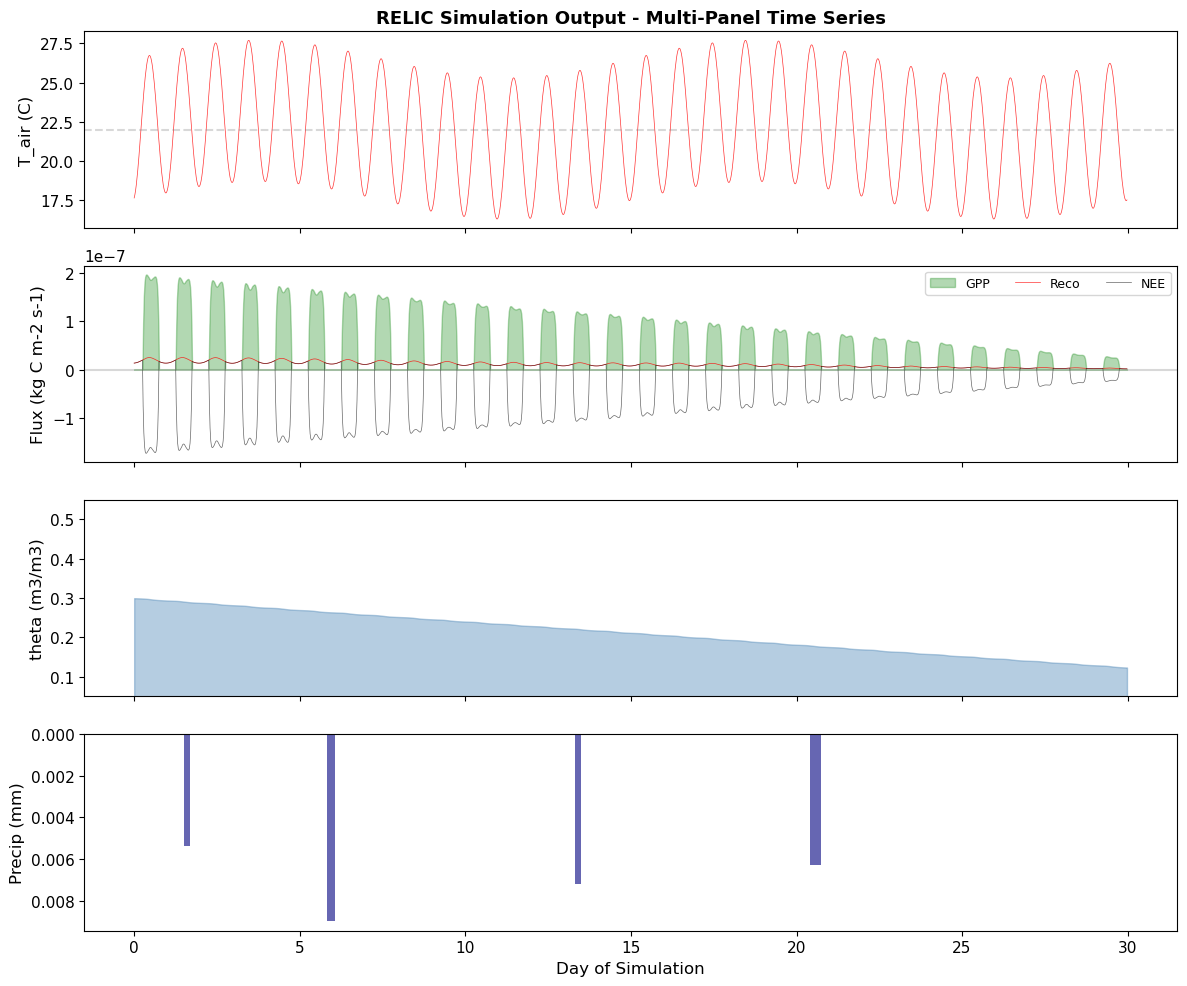

In [3]:
fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
days = time_hours / 24

# Panel 1: Temperature
ax = axes[0]
ax.plot(days, T_air, 'r-', lw=0.5, alpha=0.8)
ax.set_ylabel('T_air (C)')
ax.set_title('RELIC Simulation Output - Multi-Panel Time Series', fontweight='bold')
ax.axhline(T_mean, color='gray', ls='--', alpha=0.3)

# Panel 2: Carbon fluxes
ax = axes[1]
ax.fill_between(days, 0, GPP, alpha=0.3, color='green', label='GPP')
ax.plot(days, R_eco, 'r-', lw=0.5, alpha=0.8, label='Reco')
ax.plot(days, NEE, 'k-', lw=0.5, alpha=0.6, label='NEE')
ax.axhline(0, color='gray', ls='-', alpha=0.3)
ax.set_ylabel('Flux (kg C m-2 s-1)')
ax.legend(loc='upper right', fontsize=9, ncol=3)

# Panel 3: Soil moisture
ax = axes[2]
ax.fill_between(days, theta, alpha=0.4, color='steelblue')
ax.set_ylabel('theta (m3/m3)')
ax.set_ylim(0.05, 0.55)

# Panel 4: Precipitation
ax = axes[3]
ax.bar(days, precip, width=dt_hours/24, color='navy', alpha=0.6)
ax.set_ylabel('Precip (mm)')
ax.set_xlabel('Day of Simulation')
ax.invert_yaxis()

plt.tight_layout()
plt.show()


## 3. Diurnal Composite (Mean Diurnal Cycle)

Averaging by hour-of-day reveals the mean diurnal pattern and its variability.
Standard in flux tower analysis (Baldocchi, 2003).


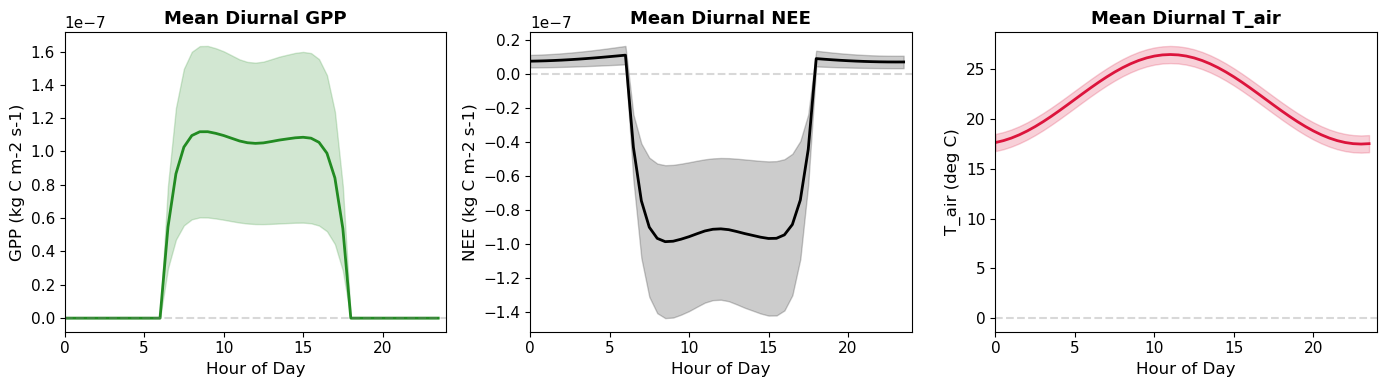

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, var, name, color, unit in [
    (axes[0], GPP, 'GPP', 'forestgreen', 'kg C m-2 s-1'),
    (axes[1], NEE, 'NEE', 'black', 'kg C m-2 s-1'),
    (axes[2], T_air, 'T_air', 'crimson', 'deg C'),
]:
    hourly_mean = torch.zeros(48)
    hourly_std = torch.zeros(48)
    for h in range(48):
        mask = (torch.arange(n_steps) % 48) == h
        hourly_mean[h] = var[mask].mean()
        hourly_std[h] = var[mask].std()
    hours = torch.arange(48) * 0.5
    ax.plot(hours, hourly_mean, color=color, lw=2)
    ax.fill_between(hours, hourly_mean - hourly_std, hourly_mean + hourly_std,
                    alpha=0.2, color=color)
    ax.set_xlabel('Hour of Day')
    ax.set_ylabel(f'{name} ({unit})')
    ax.set_title(f'Mean Diurnal {name}', fontweight='bold')
    ax.set_xlim(0, 24)
    ax.axhline(0, color='gray', ls='--', alpha=0.3)

plt.tight_layout()
plt.show()


## 4. Response Surface & Scatter Diagnostics

Light-response curves and temperature-response surfaces help diagnose
model behavior against ecological theory.


Light-response carbon boundary: n=120, max residual=2.988e-16, YAML tolerance=1.000e-06


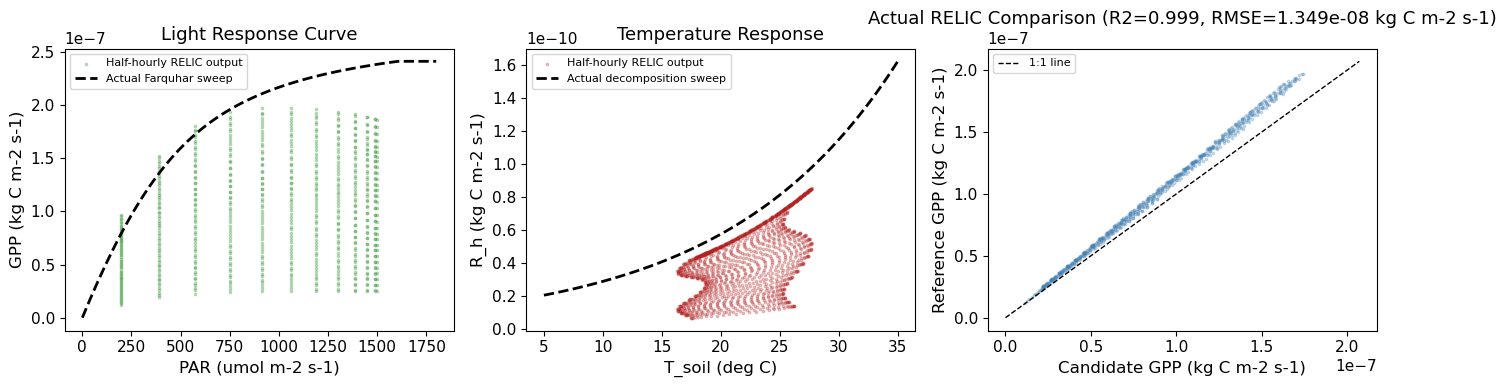

In [5]:
# ---------------------------------------------------------------
# References:
#   Farquhar et al. (1980) -- light response via actual photosynthesis module.
#   Parton et al. (1987) -- temperature response via decomposition module.
# Mathematical expression:
#   GPP = Farquhar(PAR, T, VPD, water_stress)
#   R_h = Decomposition(T_soil, theta)
# Parameter meanings:
#   par_grid: PAR sweep for the light-response diagnostic.
#   temp_grid_c: soil-temperature sweep for the respiration diagnostic.
#   GPP_candidate: perturbed RELIC run used as a comparison trajectory.
# ---------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# Light response from the actual Farquhar module
ax = axes[0]
daytime = PAR > 10.0
ax.scatter(PAR[daytime].detach().cpu().tolist(), GPP[daytime].detach().cpu().tolist(), s=3, alpha=0.25, c='forestgreen', label='Half-hourly RELIC output')
par_grid = torch.linspace(0.0, 1800.0, steps=120, dtype=torch.float64)
light_response = []
light_response_carbon_residuals = []
light_response_tolerance = float(photo.get_parameter_value(
    'conservation_tolerance', namespace='validation.conservation', required=True, validate=True,
))
# References: Farquhar (1980); photo.check_conservation_laws is the existing owner.
# Mathematical expression: A_net + R_d = A_gross; GPP = A_gross*M_C*1e-9.
# Parameter meanings: M_C is SSOT carbon molar mass; tolerance is the unchanged YAML limit.
# Units: molar ports [umol CO2 m-2 s-1], GPP [kg C m-2 s-1], relative residual [1].
# Domain/constraints: float64 input/output near compensation; no warning suppression or tolerance change.
# Sign convention: gross uptake and respiration are nonnegative; net assimilation is signed.
for par_value in par_grid:
    response_state = {
        'air_temperature': torch.tensor(298.15, dtype=torch.float64),
        'atmospheric_co2_ppm': torch.tensor(410.0, dtype=torch.float64),
        'ppfd': par_value,
        'vcmax_scaling': torch.tensor(1.0, dtype=torch.float64),
        'jmax_scaling': torch.tensor(1.0, dtype=torch.float64),
        'water_stress_factor': torch.tensor(0.9, dtype=torch.float64),
        'temperature_stress_factor': torch.tensor(1.0, dtype=torch.float64),
        'ozone_stress_factor': torch.tensor(1.0, dtype=torch.float64),
        'vapor_pressure_deficit': torch.tensor(1000.0, dtype=torch.float64),
        'leaf_area_index': torch.tensor(3.0, dtype=torch.float64),
        'leaf_water_potential': torch.tensor(-0.7, dtype=torch.float64),
    }
    response = photo.forward(response_state, time=0.0, dt=1800.0)
    carbon_residual = photo.check_conservation_laws(response_state, response)['carbon_boundary']
    assert carbon_residual <= light_response_tolerance, (
        f'Light-response carbon residual {carbon_residual} exceeds {light_response_tolerance}'
    )
    light_response_carbon_residuals.append(carbon_residual)
    light_response.append(float(unwrap_update(response['gross_primary_productivity']).detach().cpu().item()))
print(f'Light-response carbon boundary: n={len(light_response_carbon_residuals)}, '
      f'max residual={max(light_response_carbon_residuals):.3e}, YAML tolerance={light_response_tolerance:.3e}')
ax.plot(par_grid.detach().cpu().tolist(), light_response, 'k--', lw=2, label='Actual Farquhar sweep')
ax.set_xlabel('PAR (umol m-2 s-1)')
ax.set_ylabel('GPP (kg C m-2 s-1)')
ax.set_title('Light Response Curve')
ax.legend(fontsize=8)

# Temperature response from the actual decomposition module
ax = axes[1]
ax.scatter(T_air.detach().cpu().tolist(), heterotrophic_respiration.detach().cpu().tolist(), s=3, alpha=0.25, c='firebrick', label='Half-hourly RELIC output')
temp_grid_c = torch.linspace(5.0, 35.0, steps=100, dtype=torch.float32)
respiration_response = []
for temp_c in temp_grid_c:
    response = decomposition_functor.forward(
        {
            'metabolic_litter_c': torch.tensor(0.12, dtype=torch.float32),
            'structural_litter_c': torch.tensor(0.55, dtype=torch.float32),
            'fast_som_c': torch.tensor(0.90, dtype=torch.float32),
            'slow_som_c': torch.tensor(3.20, dtype=torch.float32),
            'passive_som_c': torch.tensor(5.50, dtype=torch.float32),
            'soil_temperature': temp_c + 273.15,
            'soil_moisture': torch.tensor(0.30, dtype=torch.float32),
            'lignin_n_ratio': torch.tensor(0.20, dtype=torch.float32),
            'clay_content': torch.tensor(0.25, dtype=torch.float32),
            'metabolic_litter_input': torch.tensor(0.0, dtype=torch.float32),
            'structural_litter_input': torch.tensor(0.0, dtype=torch.float32),
        },
        time=0.0,
        dt=1800.0,
    )
    respiration_response.append(float(unwrap_update(response['heterotrophic_respiration']).detach().cpu().item()) * 1.0e-3)
ax.plot(temp_grid_c.detach().cpu().tolist(), respiration_response, 'k--', lw=2, label='Actual decomposition sweep')
ax.set_xlabel('T_soil (deg C)')
ax.set_ylabel('R_h (kg C m-2 s-1)')
ax.set_title('Temperature Response')
ax.legend(fontsize=8)

# Reference vs candidate scatter from actual RELIC runs
ax = axes[2]
ax.scatter(GPP_candidate[daytime].detach().cpu().tolist(), GPP[daytime].detach().cpu().tolist(), s=3, alpha=0.25, c='steelblue')
lims_upper = max(float(GPP.max().item()), float(GPP_candidate.max().item())) * 1.05
lims = [0.0, lims_upper]
ax.plot(lims, lims, 'k--', lw=1, label='1:1 line')
rmse = torch.sqrt(torch.mean((GPP_candidate[daytime] - GPP[daytime]) ** 2))
r2 = torch.corrcoef(torch.stack([GPP_candidate[daytime], GPP[daytime]]))[0, 1] ** 2
ax.set_xlabel('Candidate GPP (kg C m-2 s-1)')
ax.set_ylabel('Reference GPP (kg C m-2 s-1)')
ax.set_title(f'Actual RELIC Comparison (R2={float(r2):.3f}, RMSE={float(rmse):.3e} kg C m-2 s-1)')
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

## 5. Coupled Flux Audit Dashboard

This dashboard inspects actual RELIC carbon-flux consistency using coupled
`GPP`, `R_eco`, and `NEE` outputs rather than synthetic pool construction.

**Reference**: RELIC flux-algebra diagnostics and structural audit workflow.


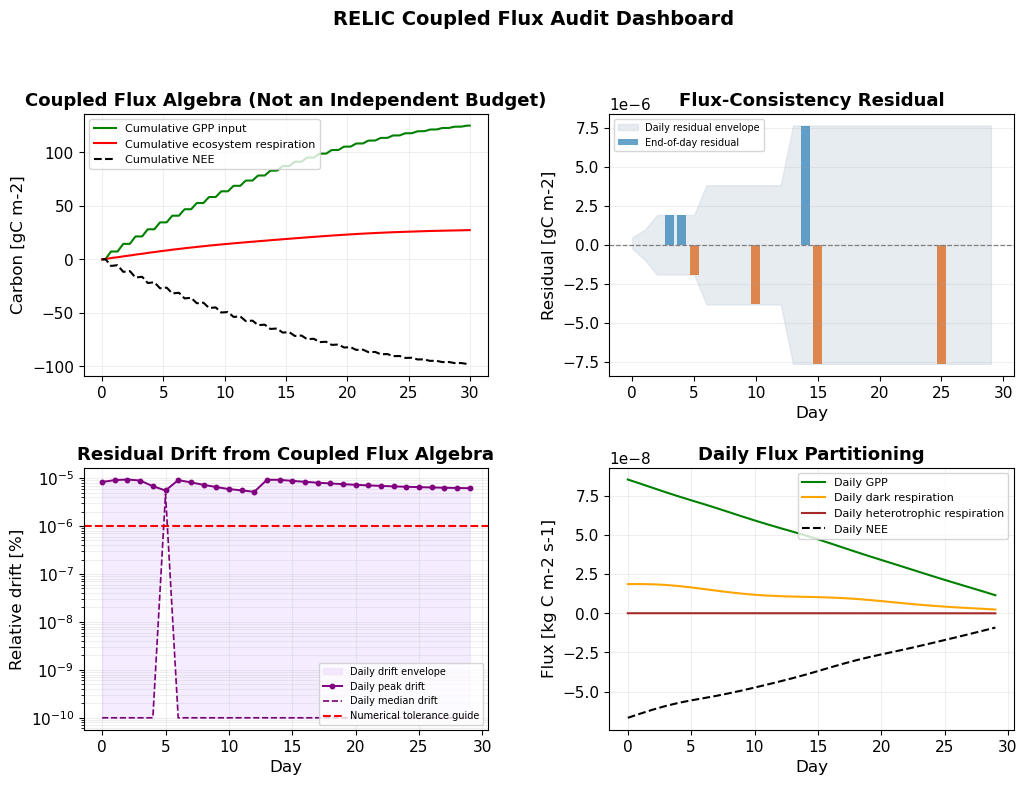

  Max coupled-flux residual: 7.629395e-06 gC m-2
  Max relative drift: 9.334068e-06%


In [6]:
# ---------------------------------------------------------------
# References:
#   Kalnay (2003) -- diagnostic use of residual sequences.
#   RELIC conservation practice: compare coupled flux terms directly instead of
#   inventing synthetic pools.
# Mathematical expression:
#   cumulative_residual = integral(GPP dt) - integral(R_eco dt) + integral(NEE dt)
# Parameter meanings:
#   carbon_conversion: converts kg C m-2 s-1 to g C m-2 per timestep.
#   consistency_drift: relative magnitude of the coupled-flux residual.
# Units:
#   Rates [kg C m-2 s-1]; integrated terms and residual [g C m-2].
# Domain/constraints:
#   NEE is derived from these same terms; the identity checks flux algebra, not independent mass closure.
# Sign convention:
#   Positive NEE is outward carbon exchange.
# ---------------------------------------------------------------
carbon_conversion = dt_hours * 3600.0 * 1000.0
cumulative_gpp = torch.cumsum(GPP * carbon_conversion, dim=0)
cumulative_reco = torch.cumsum(R_eco * carbon_conversion, dim=0)
cumulative_nee = torch.cumsum(NEE * carbon_conversion, dim=0)
carbon_residual = cumulative_gpp - cumulative_reco + cumulative_nee
consistency_drift = torch.abs(carbon_residual) / torch.maximum(torch.abs(cumulative_gpp), torch.tensor(1.0, dtype=torch.float32)) * 100.0

daily_gpp = GPP.reshape(-1, 48).mean(dim=1)
daily_dark_respiration = dark_respiration.reshape(-1, 48).mean(dim=1)
daily_heterotrophic_respiration = heterotrophic_respiration.reshape(-1, 48).mean(dim=1)
daily_nee = NEE.reshape(-1, 48).mean(dim=1)
daily_days = torch.arange(n_days, dtype=torch.float32)
daily_residual_blocks = carbon_residual.reshape(n_days, 48)
daily_residual_min = daily_residual_blocks.min(dim=1).values
daily_residual_max = daily_residual_blocks.max(dim=1).values
daily_residual_terminal = daily_residual_blocks[:, -1]
daily_drift_blocks = consistency_drift.reshape(n_days, 48)
daily_drift_peak = torch.clamp(daily_drift_blocks.max(dim=1).values, min=1.0e-10)
daily_drift_median = torch.clamp(torch.median(daily_drift_blocks, dim=1).values, min=1.0e-10)
terminal_residual_colors = [
    '#2C7FB8' if value >= 0.0 else '#D95F0E'
    for value in daily_residual_terminal.detach().cpu().tolist()
]

fig = plt.figure(figsize=(12, 8))
gs = GridSpec(2, 2, figure=fig, hspace=0.35, wspace=0.3)

ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(days.detach().cpu().tolist(), cumulative_gpp.detach().cpu().tolist(), 'g-', label='Cumulative GPP input')
ax1.plot(days.detach().cpu().tolist(), cumulative_reco.detach().cpu().tolist(), 'r-', label='Cumulative ecosystem respiration')
ax1.plot(days.detach().cpu().tolist(), cumulative_nee.detach().cpu().tolist(), 'k--', label='Cumulative NEE')
ax1.set_ylabel('Carbon [gC m-2]')
ax1.set_title('Coupled Flux Algebra (Not an Independent Budget)', fontweight='bold')
ax1.legend(fontsize=8)
ax1.grid(True, alpha=0.2)

ax2 = fig.add_subplot(gs[0, 1])
ax2.fill_between(daily_days.detach().cpu().tolist(), daily_residual_min.detach().cpu().tolist(), daily_residual_max.detach().cpu().tolist(), color='#CBD5E1', alpha=0.45, label='Daily residual envelope')
ax2.bar(daily_days.detach().cpu().tolist(), daily_residual_terminal.detach().cpu().tolist(), color=terminal_residual_colors, alpha=0.72, width=0.72, label='End-of-day residual')
ax2.axhline(0.0, color='gray', ls='--', linewidth=0.9)
ax2.set_ylabel('Residual [gC m-2]')
ax2.set_xlabel('Day')
ax2.set_title('Flux-Consistency Residual', fontweight='bold')
ax2.ticklabel_format(axis='y', style='sci', scilimits=(-2, 2))
ax2.legend(fontsize=7, loc='upper left')
ax2.grid(True, axis='y', alpha=0.2)

ax3 = fig.add_subplot(gs[1, 0])
ax3.fill_between(daily_days.detach().cpu().tolist(), daily_drift_median.detach().cpu().tolist(), daily_drift_peak.detach().cpu().tolist(), color='#E9D5FF', alpha=0.45, label='Daily drift envelope')
ax3.semilogy(daily_days.detach().cpu().tolist(), daily_drift_peak.detach().cpu().tolist(), color='purple', lw=1.4, marker='o', markersize=3.2, label='Daily peak drift')
ax3.semilogy(daily_days.detach().cpu().tolist(), daily_drift_median.detach().cpu().tolist(), color='#7A0177', lw=1.2, ls='--', label='Daily median drift')
ax3.axhline(1.0e-6, color='red', ls='--', label='Numerical tolerance guide')
ax3.set_ylabel('Relative drift [%]')
ax3.set_xlabel('Day')
ax3.set_title('Residual Drift from Coupled Flux Algebra', fontweight='bold')
ax3.legend(fontsize=7, loc='lower right')
ax3.grid(True, which='both', alpha=0.2)

ax4 = fig.add_subplot(gs[1, 1])
ax4.plot(daily_days.detach().cpu().tolist(), daily_gpp.detach().cpu().tolist(), 'g-', label='Daily GPP')
ax4.plot(daily_days.detach().cpu().tolist(), daily_dark_respiration.detach().cpu().tolist(), color='orange', label='Daily dark respiration')
ax4.plot(daily_days.detach().cpu().tolist(), daily_heterotrophic_respiration.detach().cpu().tolist(), color='brown', label='Daily heterotrophic respiration')
ax4.plot(daily_days.detach().cpu().tolist(), daily_nee.detach().cpu().tolist(), 'k--', label='Daily NEE')
ax4.set_ylabel('Flux [kg C m-2 s-1]')
ax4.set_xlabel('Day')
ax4.set_title('Daily Flux Partitioning', fontweight='bold')
ax4.legend(fontsize=8)
ax4.grid(True, alpha=0.2)

fig.suptitle('RELIC Coupled Flux Audit Dashboard', fontsize=14, fontweight='bold', y=1.01)
plt.show()
print(f"  Max coupled-flux residual: {float(torch.max(torch.abs(carbon_residual))):.6e} gC m-2")
print(f"  Max relative drift: {float(torch.max(consistency_drift)):.6e}%")

## 6. Functor Dependency Graph Visualization

Visualize the DAG structure of registered Functors using RELIC's
`topology_algebra.build_incidence_matrix`.

This is a metadata-derived variable-flow graph, not a registered or compiled
execution plan. Its incidence matrix is not a physical conservation proof.


=== Metadata-Derived RELIC Variable-Flow Graph ===
  Graph nodes: 4
  Graph edges: 2
  Incidence matrix shape: (4, 2)
  Rank(B): 2
  Betti number: 0
  Is DAG: True
  Candidate topological order: ['photosynthesis', 'evapotranspiration', 'soil_moisture', 'decomposition']

Variable flow edges:
  evapotranspiration --[evapotranspiration_flux]--> soil_moisture
  soil_moisture --[soil_moisture]--> decomposition


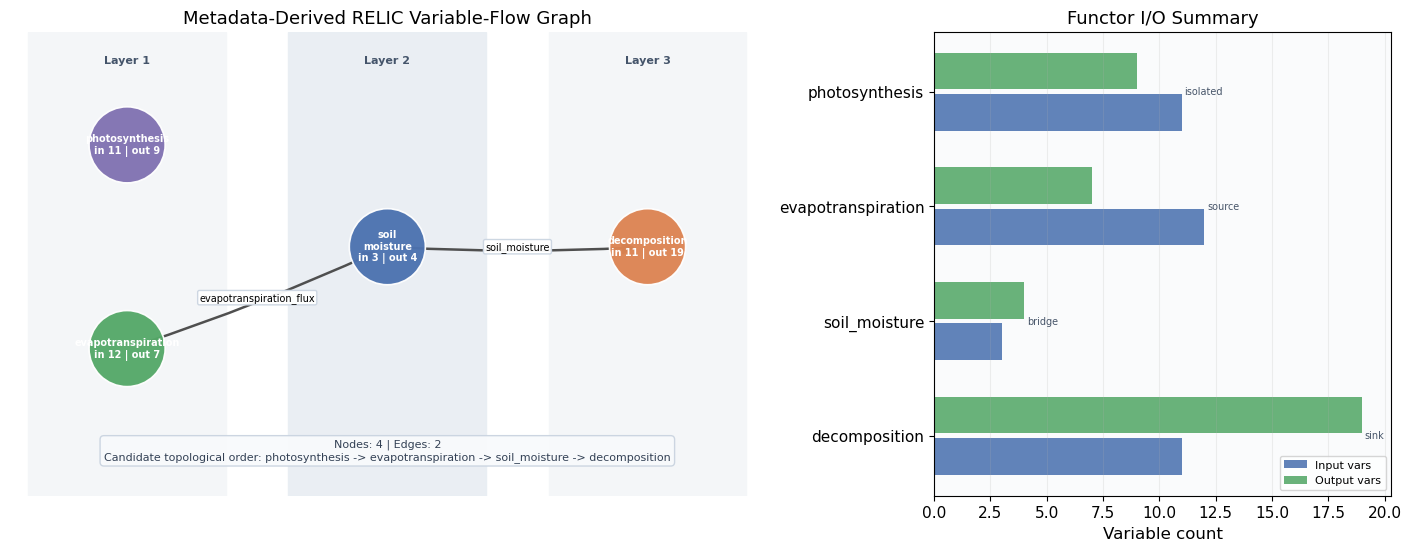

In [7]:
# === NB22.6: Dependency Graph and Functor Registration ===
# ---------------------------------------------------------------
# References:
#   Godsil and Royle (2001) -- incidence matrices and graph topology.
# Mathematical expression:
#   B[i, j] = -1 for source node, +1 for target node, 0 otherwise.
# Parameter meanings:
#   graph_ir: orchestration graph assembled from actual Functor metadata.
#   betti_number: cycle rank derived from the incidence matrix.
# Units:
#   Graph incidence, ranks and cycle counts [1].
# Domain/constraints:
#   Metadata-derived software graph; not a registered execution plan or physical ledger.
# Sign convention:
#   Incidence is -1 at source and +1 at target.
# ---------------------------------------------------------------
import networkx as nx

from relic.orchestration.graph_ir import GraphIR, NodeSpec
from relic.orchestration.topology_algebra import build_incidence_matrix, compute_cycle_rank, compute_rank


def variable_names(variables):
    names = []
    for variable in variables or []:
        if isinstance(variable, str):
            names.append(variable)
        else:
            names.append(getattr(variable, 'name', str(variable)))
    return names


actual_functors = {
    'photosynthesis': photo,
    'evapotranspiration': et_functor,
    'soil_moisture': bucket_functor,
    'decomposition': decomposition_functor,
}

functor_inputs = {}
functor_outputs = {}
output_owner = {}
for node_name, functor in actual_functors.items():
    metadata = functor.metadata
    functor_inputs[node_name] = variable_names(getattr(metadata, 'input_variables', []))
    functor_outputs[node_name] = variable_names(getattr(metadata, 'output_variables', []))
    for output_name in functor_outputs[node_name]:
        output_owner[output_name] = node_name

graph_nodes = {}
edge_labels = {}
for node_name, functor in actual_functors.items():
    node_inputs = {}
    for input_name in functor_inputs[node_name]:
        if input_name in output_owner and output_owner[input_name] != node_name:
            source_node = output_owner[input_name]
            node_inputs[input_name] = {'link': [source_node, input_name]}
            edge_labels[(source_node, node_name)] = input_name
        else:
            node_inputs[input_name] = {'source': 'external'}
    graph_nodes[node_name] = NodeSpec(
        class_type=functor.__class__.__name__,
        inputs=node_inputs,
        outputs=functor_outputs[node_name],
        config={},
    )

graph_ir = GraphIR(schema_version='1.0', nodes=graph_nodes)
B, node_ids, _ = build_incidence_matrix(graph_ir)
rank = compute_rank(B)
betti_number = compute_cycle_rank(B)

G = nx.DiGraph()
for node_name, functor in actual_functors.items():
    G.add_node(node_name, class_type=functor.__class__.__name__)
for (source_node, target_node), variable_name in edge_labels.items():
    G.add_edge(source_node, target_node, variable=variable_name)

print("=== Metadata-Derived RELIC Variable-Flow Graph ===")
print(f"  Graph nodes: {G.number_of_nodes()}")
print(f"  Graph edges: {G.number_of_edges()}")
print(f"  Incidence matrix shape: {B.shape}")
print(f"  Rank(B): {rank}")
print(f"  Betti number: {betti_number}")
print(f"  Is DAG: {nx.is_directed_acyclic_graph(G)}")
if nx.is_directed_acyclic_graph(G):
    print(f"  Candidate topological order: {list(nx.topological_sort(G))}")

print()
print('Variable flow edges:')
for source_node, target_node, data in G.edges(data=True):
    print(f"  {source_node} --[{data['variable']}]--> {target_node}")

if nx.is_directed_acyclic_graph(G):
    generations = list(nx.topological_generations(G))
else:
    generations = [list(G.nodes())]
layer_lookup = {}
positions = {}
for layer_index, nodes_in_layer in enumerate(generations):
    if len(nodes_in_layer) == 1:
        y_coords = [0.0]
    else:
        y_coords = torch.linspace(0.36, -0.36, steps=len(nodes_in_layer)).tolist()
    for node_name, y_coord in zip(nodes_in_layer, y_coords):
        layer_lookup[node_name] = layer_index
        positions[node_name] = (float(layer_index), float(y_coord))
nx.set_node_attributes(G, layer_lookup, 'layer')
wrapped_labels = {
    node_name: node_name.replace('_', chr(10)) + chr(10) + f'in {len(functor_inputs[node_name])} | out {len(functor_outputs[node_name])}'
    for node_name in G.nodes()
}
node_colors = []
functor_roles = {}
for node_name in G.nodes():
    indegree = G.in_degree(node_name)
    outdegree = G.out_degree(node_name)
    if indegree == 0 and outdegree > 0:
        node_colors.append('#55A868')
        functor_roles[node_name] = 'source'
    elif indegree > 0 and outdegree == 0:
        node_colors.append('#DD8452')
        functor_roles[node_name] = 'sink'
    elif indegree == 0 and outdegree == 0:
        node_colors.append('#8172B2')
        functor_roles[node_name] = 'isolated'
    else:
        node_colors.append('#4C72B0')
        functor_roles[node_name] = 'bridge'

fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), constrained_layout=True, gridspec_kw={'width_ratios': [1.65, 1.0]})
for layer_index in range(len(generations)):
    band_color = '#F4F6F8' if layer_index % 2 == 0 else '#E9EEF3'
    axes[0].axvspan(layer_index - 0.38, layer_index + 0.38, color=band_color, alpha=0.95, zorder=0)
    axes[0].text(float(layer_index), 0.66, f'Layer {layer_index + 1}', ha='center', va='center', fontsize=8, fontweight='bold', color='#44546A')
nx.draw_networkx_nodes(
    G,
    positions,
    ax=axes[0],
    node_color=node_colors,
    node_size=3000,
    alpha=0.96,
    linewidths=1.2,
    edgecolors='white',
)
nx.draw_networkx_edges(
    G,
    positions,
    ax=axes[0],
    arrows=True,
    arrowsize=18,
    width=1.8,
    edge_color='#4F4F4F',
    connectionstyle='arc3,rad=0.03',
)
nx.draw_networkx_labels(
    G,
    positions,
    ax=axes[0],
    labels=wrapped_labels,
    font_size=7,
    font_weight='bold',
    font_color='white',
)
nx.draw_networkx_edge_labels(
    G,
    positions,
    nx.get_edge_attributes(G, 'variable'),
    ax=axes[0],
    font_size=7,
    rotate=False,
    bbox={'boxstyle': 'round,pad=0.18', 'facecolor': 'white', 'edgecolor': '#CBD5E1', 'alpha': 0.95},
)
graph_summary = [
    f'Nodes: {G.number_of_nodes()} | Edges: {G.number_of_edges()}',
    'Candidate topological order: ' + ' -> '.join(list(nx.topological_sort(G))) if nx.is_directed_acyclic_graph(G) else 'Candidate topological order: n/a',
]
axes[0].text(
    1.0,
    -0.68,
    chr(10).join(graph_summary),
    ha='center',
    va='top',
    fontsize=8,
    color='#334155',
    bbox={'boxstyle': 'round,pad=0.35', 'facecolor': '#F8FAFC', 'edgecolor': '#CBD5E1', 'alpha': 0.98},
)
axes[0].set_title('Metadata-Derived RELIC Variable-Flow Graph')
axes[0].set_xlim(-0.45, max(0.55, len(generations) - 0.55))
axes[0].set_ylim(-0.88, 0.76)
axes[0].axis('off')

functor_names = list(actual_functors.keys())
y_positions = list(range(len(functor_names)))
input_counts = [len(functor_inputs[name]) for name in functor_names]
output_counts = [len(functor_outputs[name]) for name in functor_names]
axes[1].set_facecolor('#FAFBFC')
axes[1].barh([value + 0.18 for value in y_positions], input_counts, height=0.32, color='#4C72B0', alpha=0.88, label='Input vars')
axes[1].barh([value - 0.18 for value in y_positions], output_counts, height=0.32, color='#55A868', alpha=0.88, label='Output vars')
axes[1].set_yticks(y_positions)
axes[1].set_yticklabels(functor_names)
axes[1].invert_yaxis()
axes[1].set_xlabel('Variable count')
axes[1].set_title('Functor I/O Summary')
axes[1].legend(fontsize=8, loc='lower right')
axes[1].grid(True, axis='x', alpha=0.2)
axes[1].set_xlim(0, max(max(input_counts), max(output_counts)) + 1.3)
for index, functor_name in enumerate(functor_names):
    axes[1].text(
        max(input_counts[index], output_counts[index]) + 0.12,
        index,
        functor_roles[functor_name],
        va='center',
        fontsize=7,
        color='#475569',
    )

plt.show()

## Summary

This notebook demonstrated **5 standard visualization patterns** for actual RELIC output:

| Pattern | Use Case |
|---|---|
| Multi-panel time series | Overview of forcing and coupled state variables |
| Diurnal composite | Mean daily cycle with uncertainty bands |
| Response diagnostics | Actual module sweeps and candidate-vs-reference comparison |
| Coupled flux audit dashboard | Flux consistency residuals and daily partitioning |
| Dependency graph | Functor DAG structure from actual metadata |

All plots use `matplotlib` with publication defaults (300 DPI, proper labels).
For interactive plots, consider `plotly` (see `relic.interfaces.web`).
